# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y evaluación de mejoras al modelo (Semana 14, reto tercer corte)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist  
Estudiante: David Santiago Pedraza Ochoa (Santi) · **ID 25** (semilla `1025`)

Objetivo: comprobar si reducir las variables numéricas con PCA y cambiar la fuerza de la regularización (`C`) mejora la predicción de entregas tardías respecto al modelo de referencia, y contrastar con Kolmogorov-Smirnov si `valor_flete` se distribuye de forma similar en entrenamiento y validación.

Se mantienen el problema, el ID, la semilla, la muestra de 35.000 pedidos y las particiones de la semana 12. Los 5.250 pedidos de prueba **no se usan** para elegir el modelo.

## 1. Carga de datos

Se vuelven a integrar las siete tablas de Olist (misma copia pública con revisión fija que en la semana 12), de modo que el cuaderno se ejecuta desde cero en Google Colab.

In [1]:
import hashlib
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

Path('reports').mkdir(parents=True, exist_ok=True)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Mismo procesamiento de la semana 12: un registro por pedido, variable objetivo `is_late` y predictores disponibles al cierre de la compra (sin fechas reales de entrega ni reseñas posteriores).

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual y particiones (ID 25)

Es la misma celda de la semana 12: el mismo ID produce la misma muestra y las mismas particiones. La huella de la muestra debe ser `2bceba3982e4`, igual que en el reporte de la semana 12.

In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 25
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 25 | Semilla: 1025
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 2bceba3982e4


In [8]:
assert huella_muestra == '2bceba3982e4', (
    'La huella no coincide con la de la semana 12 (2bceba3982e4). Revise el ID y la fuente de datos.')
print('Huella verificada: la muestra es la misma de la semana 12.')
print('Prevalencia de tardíos | muestra:', round(muestra['is_late'].mean(), 4),
      '| train:', round(y_train.mean(), 4), '| valid:', round(y_valid.mean(), 4))

Huella verificada: la muestra es la misma de la semana 12.
Prevalencia de tardíos | muestra: 0.0677 | train: 0.0678 | valid: 0.0678


## 3. Actividad 1. PCA y varianza explicada

PCA se aplica **solo a las variables numéricas** y se ajusta únicamente con entrenamiento: primero se imputan los faltantes (mediana), luego se estandarizan y después se calculan las componentes con `svd_solver='full'` (SVD). Las cuatro variables categóricas siguen su propia ruta con One-Hot Encoding. El criterio de trabajo es conservar el mínimo de componentes que explique al menos el 90 % de la varianza.

In [9]:
UMBRAL_VARIANZA = 0.90

prep_numerico = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
X_train_num = prep_numerico.fit_transform(train[columnas_numericas])   # solo entrenamiento

pca_completo = PCA(svd_solver='full').fit(X_train_num)
varianza = pca_completo.explained_variance_ratio_
varianza_acum = np.cumsum(varianza)
n_componentes = int(np.argmax(varianza_acum >= UMBRAL_VARIANZA) + 1)

tabla_varianza = pd.DataFrame({
    'componente': np.arange(1, len(varianza) + 1),
    'varianza_pct': 100 * varianza,
    'acumulada_pct': 100 * varianza_acum,
}).round(2)

print('Variables numéricas iniciales:', len(columnas_numericas))
print('Componentes que explican al menos el 90 %:', n_componentes,
      f'(varianza acumulada = {100 * varianza_acum[n_componentes - 1]:.2f} %)')
print(f'Con {n_componentes - 1} componentes: {100 * varianza_acum[n_componentes - 2]:.2f} %')
print(f'Varianza que queda en las {len(columnas_numericas) - n_componentes} componentes descartadas:',
      f'{100 * (1 - varianza_acum[n_componentes - 1]):.2f} %\n')
print(tabla_varianza.to_string(index=False))

Variables numéricas iniciales: 24
Componentes que explican al menos el 90 %: 15 (varianza acumulada = 90.60 %)
Con 14 componentes: 87.44 %
Varianza que queda en las 9 componentes descartadas: 9.40 %

 componente  varianza_pct  acumulada_pct
          1         19.24          19.24
          2          9.52          28.76
          3          7.69          36.46
          4          7.44          43.90
          5          7.32          51.22
          6          5.04          56.26
          7          4.31          60.57
          8          4.22          64.79
          9          4.19          68.98
         10          4.12          73.10
         11          3.92          77.01
         12          3.64          80.65
         13          3.54          84.19
         14          3.26          87.44
         15          3.16          90.60
         16          2.44          93.03
         17          1.83          94.87
         18          1.57          96.44
         19          

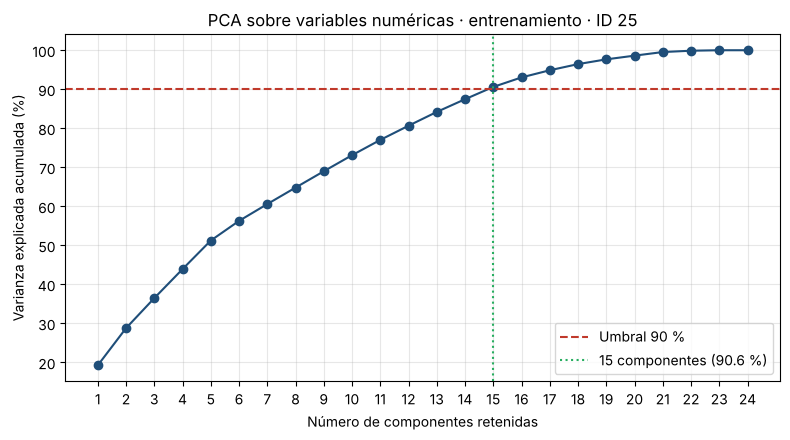

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(1, len(varianza_acum) + 1)
ax.plot(x, 100 * varianza_acum, marker='o', color='#1f4e79')
ax.axhline(100 * UMBRAL_VARIANZA, color='#c0392b', linestyle='--', label='Umbral 90 %')
ax.axvline(n_componentes, color='#27ae60', linestyle=':',
           label=f'{n_componentes} componentes ({100 * varianza_acum[n_componentes - 1]:.1f} %)')
ax.set_xlabel('Número de componentes retenidas')
ax.set_ylabel('Varianza explicada acumulada (%)')
ax.set_title('PCA sobre variables numéricas · entrenamiento · ID 25')
ax.set_xticks(x)
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig('reports/S14_varianza_acumulada_ID_25.png', dpi=150)
plt.show()

In [11]:
# ¿Qué variables pesan en las primeras componentes? (descriptivo, no causal)
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=columnas_numericas,
                      columns=['CP1', 'CP2', 'CP3'])
for cp in cargas.columns:
    top = cargas[cp].abs().sort_values(ascending=False).head(5).index
    print(cp, '->', ', '.join(f'{v} ({cargas.loc[v, cp]:+.2f})' for v in top))

# Pares de variables numéricas más correlacionadas (en entrenamiento, ya estandarizadas)
corr = pd.DataFrame(X_train_num, columns=columnas_numericas).corr().abs()
pares = (corr.where(np.triu(np.ones(corr.shape), k=1) == 1).stack()
         .sort_values(ascending=False).head(6).round(3))
print('\nPares más correlacionados (|r|):')
print(pares.to_string())

CP1 -> valor_pagado (+0.41), valor_productos (+0.39), peso_total_g (+0.35), precio_maximo (+0.35), volumen_total_cm3 (+0.33)
CP2 -> proporcion_flete (+0.39), precio_maximo (-0.36), cantidad_items (+0.33), valor_flete (+0.30), cantidad_productos (+0.28)
CP3 -> vendedor_mismo_estado (+0.50), dias_prometidos (-0.49), vendedor_misma_ciudad (+0.36), dia_semana_compra (-0.32), compra_fin_semana (-0.32)

Pares más correlacionados (|r|):
valor_productos    valor_pagado         0.995
                   precio_maximo        0.946
precio_maximo      valor_pagado         0.931
peso_total_g       peso_maximo_g        0.864
                   volumen_total_cm3    0.857
dia_semana_compra  compra_fin_semana    0.770


### Interpretación 1. PCA

**Respuesta:** Partí de **24 variables numéricas** y, con el umbral del 90 %, se conservaron **15 componentes**, que explican **90.60 %** de la varianza (con 14 solo se llega a 87.44 %, por eso hacen falta 15). Se descartan 9 componentes, es decir 37.5 % de las dimensiones numéricas, una reducción moderada: la primera componente explica apenas 19.24 % y la segunda 9.52 %, o sea que la varianza está repartida y las variables numéricas son menos redundantes de lo que se esperaría. La redundancia sí existe en grupos concretos: `valor_productos` y `valor_pagado` (|r| = 0.995), `valor_productos` y `precio_maximo` (0.946), `peso_total_g` y `peso_maximo_g` (0.864), `peso_total_g` y `volumen_total_cm3` (0.857).

Lectura descriptiva de las componentes (un peso grande no implica causalidad): CP1 pesa sobre todo en `valor_pagado`, `valor_productos`, `peso_total_g`, `precio_maximo` y `volumen_total_cm3` (cargas de 0.33 a 0.41), así que resume el tamaño y valor del pedido; CP2 contrasta `proporcion_flete`, `cantidad_items` y `valor_flete` frente a `precio_maximo`; CP3 reúne `vendedor_mismo_estado` y `vendedor_misma_ciudad` frente a `dias_prometidos`.

**Utilidad y pérdida de información:** PCA resume variables relacionadas y reduce la dimensión numérica, pero se pierde el 9.40 % de la varianza que queda en las 9 componentes descartadas y se pierde la interpretación variable por variable. Además, PCA no mira `is_late`: maximizar varianza no es maximizar capacidad predictiva, y una dirección de poca varianza podría ser justo la que separa entregas tardías de puntuales. Si eso ocurrió se ve en la comparación de modelos (sección 4). Por último, PCA solo reduce la parte numérica: el clasificador recibe 140 columnas con PCA (15 componentes + 125 columnas One-Hot) frente a 149 sin PCA (24 + 125).

## 4. Actividad 2. Comparación de las cuatro configuraciones

Los cuatro experimentos usan la misma muestra, la misma partición de validación, el umbral de clasificación 0,50 y `class_weight='balanced'`. Solo cambian la reducción de dimensión y `C`:

| Experimento | Transformación numérica | C |
|---|---|---|
| A. Referencia | Sin PCA | 1.0 |
| B. Reducción de dimensión | PCA 90 % | 1.0 |
| C. Mayor penalización | PCA 90 % | 0.1 |
| D. Menor penalización | PCA 90 % | 10.0 |

Imputación, escala, PCA y el clasificador se ajustan **solo con entrenamiento** dentro de un `Pipeline`; validación solo se transforma.

In [12]:
def construir_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=UMBRAL_VARIANZA, svd_solver='full'))
    preproc = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    return make_pipeline(preproc, LogisticRegression(C=C, class_weight='balanced',
                                                     max_iter=1000))

EXPERIMENTOS = {
    'A': {'descripcion': 'Referencia: variables numéricas sin PCA', 'pca': False, 'C': 1.0},
    'B': {'descripcion': 'PCA 90 % de varianza', 'pca': True, 'C': 1.0},
    'C': {'descripcion': 'PCA 90 % de varianza, mayor penalización', 'pca': True, 'C': 0.1},
    'D': {'descripcion': 'PCA 90 % de varianza, menor penalización', 'pca': True, 'C': 10.0},
}
UMBRAL_CLASIFICACION = 0.50
COSTO_FP, COSTO_FN = 8, 35   # supuesto didáctico, no costos reales de Olist

modelos, preds, probas, filas = {}, {}, {}, []
for nombre, cfg in EXPERIMENTOS.items():
    m = construir_modelo(cfg['pca'], cfg['C'])
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        m.fit(X_train, y_train)
    convergio = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)

    proba = m.predict_proba(X_valid)[:, 1]
    pred = (proba >= UMBRAL_CLASIFICACION).astype(int)
    assert np.array_equal(pred, m.predict(X_valid))   # mismo umbral 0.50 en los cuatro
    pred_train = (m.predict_proba(X_train)[:, 1] >= UMBRAL_CLASIFICACION).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

    ultimo = m[0].named_transformers_['numericas'][-1]
    n_num = getattr(ultimo, 'n_components_', len(columnas_numericas))
    n_cols = m[0].transform(X_valid.iloc[:5]).shape[1]

    modelos[nombre], preds[nombre], probas[nombre] = m, pred, proba
    filas.append({
        'experimento': nombre, 'descripcion': cfg['descripcion'],
        'pca': cfg['pca'], 'C': cfg['C'], 'convergio': convergio,
        'variables_numericas_salida': int(n_num), 'columnas_clasificador': int(n_cols),
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred, zero_division=0),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'f1_train': f1_score(y_train, pred_train, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, proba),
        'ap': average_precision_score(y_valid, proba),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'alertas': int(pred.sum()),
        'costo_brl': float(COSTO_FP * fp + COSTO_FN * fn),
    })

resultados = pd.DataFrame(filas).set_index('experimento')
print('Prevalencia de tardíos en validación:', round(y_valid.mean(), 3),
      '| tardíos reales:', int(y_valid.sum()), 'de', len(y_valid))
print('¿Los cuatro convergieron?', bool(resultados['convergio'].all()), '\n')
metricas = ['accuracy', 'precision', 'recall', 'f1', 'ap', 'roc_auc']
print(resultados[['pca', 'C', 'variables_numericas_salida', 'columnas_clasificador'] + metricas]
      .round(4).to_string())

# ¿Sobreajuste? F1 en entrenamiento frente a validación (mismo umbral 0.50)
sobreajuste = resultados[['f1_train', 'f1']].rename(columns={'f1': 'f1_valid'})
sobreajuste['brecha_train_menos_valid'] = sobreajuste['f1_train'] - sobreajuste['f1_valid']
print('\nF1 en entrenamiento y en validación:')
print(sobreajuste.round(4).to_string())

Prevalencia de tardíos en validación: 0.068 | tardíos reales: 356 de 5250
¿Los cuatro convergieron? True 

               pca     C  variables_numericas_salida  columnas_clasificador  accuracy  precision  recall      f1      ap  roc_auc
experimento                                                                                                                      
A            False   1.0                          24                    149    0.6570     0.1187  0.6320  0.1999  0.1475   0.6986
B             True   1.0                          15                    140    0.6451     0.1102  0.5983  0.1861  0.1280   0.6696
C             True   0.1                          15                    140    0.6434     0.1101  0.6011  0.1861  0.1298   0.6711
D             True  10.0                          15                    140    0.6440     0.1103  0.6011  0.1863  0.1281   0.6677

F1 en entrenamiento y en validación:
             f1_train  f1_valid  brecha_train_menos_valid
experimento      

In [13]:
# Diferencias frente a la referencia A y frente a B (efecto de PCA y de C)
dif = resultados[metricas].copy()
dif_vs_A = (dif - dif.loc['A']).round(4)
dif_vs_B = (dif - dif.loc['B']).round(4)
print('--- Diferencia frente a A (B: efecto de PCA) ---')
print(dif_vs_A.loc[['B', 'C', 'D']].to_string())
print('\n--- Diferencia frente a B (C y D: efecto de C con PCA) ---')
print(dif_vs_B.loc[['C', 'D']].to_string())

print('\nMatrices de confusión en validación (filas: real, columnas: predicho)')
for nombre in EXPERIMENTOS:
    r = resultados.loc[nombre]
    print(f'\n{nombre}  C={r["C"]}  PCA={r["pca"]}')
    print(pd.DataFrame([[r['tn'], r['fp']], [r['fn'], r['tp']]],
                       index=['real a tiempo (0)', 'real tardío (1)'],
                       columns=['pred a tiempo (0)', 'pred tardío (1)']))

--- Diferencia frente a A (B: efecto de PCA) ---
             accuracy  precision  recall      f1      ap  roc_auc
experimento                                                      
B             -0.0118    -0.0085 -0.0337 -0.0138 -0.0195  -0.0289
C             -0.0135    -0.0087 -0.0309 -0.0138 -0.0177  -0.0274
D             -0.0130    -0.0085 -0.0309 -0.0136 -0.0194  -0.0309

--- Diferencia frente a B (C y D: efecto de C con PCA) ---
             accuracy  precision  recall      f1      ap  roc_auc
experimento                                                      
C             -0.0017    -0.0001  0.0028 -0.0000  0.0019   0.0015
D             -0.0011     0.0001  0.0028  0.0002  0.0002  -0.0020

Matrices de confusión en validación (filas: real, columnas: predicho)

A  C=1.0  PCA=False
                   pred a tiempo (0)  pred tardío (1)
real a tiempo (0)               3224             1670
real tardío (1)                  131              225

B  C=1.0  PCA=True
                   pred

### Interpretación 2. Sin PCA frente a PCA, y efecto de `C`

**Respuesta:** El modelo **A (sin PCA, C = 1.0) quedó por encima de B, C y D en todas las métricas**: Accuracy 0.657, Precision 0.119, Recall 0.632, F1 0.200, Average Precision 0.147 y ROC-AUC 0.699.

**Efecto de PCA (B frente a A, mismo C = 1.0):** todas las métricas bajan. El Recall pasa de 0.632 a 0.598 (213 de 356 tardíos detectados en lugar de 225, es decir 12 retrasos más sin detectar), el F1 de 0.200 a 0.186, la AP de 0.147 a 0.128 y el ROC-AUC de 0.699 a 0.670. Como AP y ROC-AUC no dependen del umbral de 0.50, el ordenamiento de los pedidos por riesgo también empeoró, no solo el punto de corte. Mi lectura, que es una inferencia y no algo que probé, es que las 9 componentes descartadas (9.40 % de la varianza) contenían algo de información útil para distinguir entregas tardías. La reducción de 24 a 15 variables numéricas no se tradujo en un modelo mejor.

**Efecto de la regularización (C y D frente a B):** casi no hay diferencia. Con C = 0.1 y C = 10.0 el Recall es 0.601 en ambos (B: 0.598), el F1 es 0.186 en los tres, y la AP es 0.130 (C), 0.128 (D) y 0.128 (B). La diferencia máxima es un pedido tardío detectado de más (214 frente a 213). Esto es coherente con que no hay sobreajuste que corregir: el F1 en entrenamiento y en validación es casi igual en los cuatro modelos (A: 0.211 y 0.200; B, C y D: 0.200 y 0.186, una brecha menor a 0.015), y con 24.500 pedidos y 140 columnas la penalización pesa poco. El límite del modelo no parece ser que memorice, sino su capacidad para separar las clases (AP de 0.128 a 0.147 frente a una prevalencia de 0.068). Por eso **no afirmo que C = 0.1 sea mejor que C = 10.0 ni al revés**: las diferencias son demasiado pequeñas para sostener esa conclusión.

**Limitaciones:** todo se midió en una sola partición de validación y no se aplicó ninguna prueba estadística de comparación entre modelos, de modo que las diferencias son observaciones sobre esta muestra, no evidencia de superioridad estadística.

## 5. Actividad 3. Falsos positivos, falsos negativos y costo didáctico

Se retoma el supuesto de la semana 12: **R$ 8 por falso positivo** y **R$ 35 por falso negativo**. Son cifras didácticas, no costos observados de Olist. Costo = 8·FP + 35·FN.

In [14]:
# Referencia trivial: siempre predice "a tiempo" (misma que en la semana 12)
referencia = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)
tn_r, fp_r, fn_r, tp_r = confusion_matrix(y_valid, pred_ref).ravel()
costo_referencia = COSTO_FP * fp_r + COSTO_FN * fn_r
costo_alertar_todo = COSTO_FP * int((y_valid == 0).sum())   # alertar los 5.250 pedidos

tabla_costos = resultados[['fp', 'fn', 'alertas']].copy()
tabla_costos['costo_fp_brl'] = COSTO_FP * tabla_costos['fp']
tabla_costos['costo_fn_brl'] = COSTO_FN * tabla_costos['fn']
tabla_costos['costo_total_brl'] = tabla_costos['costo_fp_brl'] + tabla_costos['costo_fn_brl']
tabla_costos['dif_vs_A_brl'] = tabla_costos['costo_total_brl'] - tabla_costos.loc['A', 'costo_total_brl']
tabla_costos['dif_vs_B_brl'] = tabla_costos['costo_total_brl'] - tabla_costos.loc['B', 'costo_total_brl']
assert np.allclose(tabla_costos['costo_total_brl'], resultados['costo_brl'])
print(tabla_costos.to_string())

print(f'\nReferencia "siempre a tiempo": FP = {fp_r} | FN = {fn_r} | '
      f'Accuracy = {accuracy_score(y_valid, pred_ref):.3f} | Recall = 0 | Costo = R$ {costo_referencia:,.0f}')
mejor = tabla_costos['costo_total_brl'].idxmin()
print(f'Menor costo entre A-D: {mejor} (R$ {tabla_costos.loc[mejor, "costo_total_brl"]:,.0f}); '
      f'excede a la referencia trivial en R$ {tabla_costos.loc[mejor, "costo_total_brl"] - costo_referencia:,.0f} '
      f'({100 * (tabla_costos.loc[mejor, "costo_total_brl"] / costo_referencia - 1):.1f} %)')

print(f'Referencia "alertar todos los pedidos": Recall = 1 | Costo = R$ {costo_alertar_todo:,.0f}')
precision_equilibrio = COSTO_FP / (COSTO_FP + COSTO_FN)
print(f'Precisión mínima para que alertar compense con estos costos: {precision_equilibrio:.3f}')
print('Precisión alcanzada:', resultados['precision'].round(3).to_dict())

               fp   fn  alertas  costo_fp_brl  costo_fn_brl  costo_total_brl  dif_vs_A_brl  dif_vs_B_brl
experimento                                                                                             
A            1670  131     1895         13360          4585            17945             0          -820
B            1720  143     1933         13760          5005            18765           820             0
C            1730  142     1944         13840          4970            18810           865            45
D            1727  142     1941         13816          4970            18786           841            21

Referencia "siempre a tiempo": FP = 0 | FN = 356 | Accuracy = 0.932 | Recall = 0 | Costo = R$ 12,460
Menor costo entre A-D: A (R$ 17,945); excede a la referencia trivial en R$ 5,485 (44.0 %)
Referencia "alertar todos los pedidos": Recall = 1 | Costo = R$ 39,152
Precisión mínima para que alertar compense con estos costos: 0.186
Precisión alcanzada: {'A': 0.119, 'B': 0

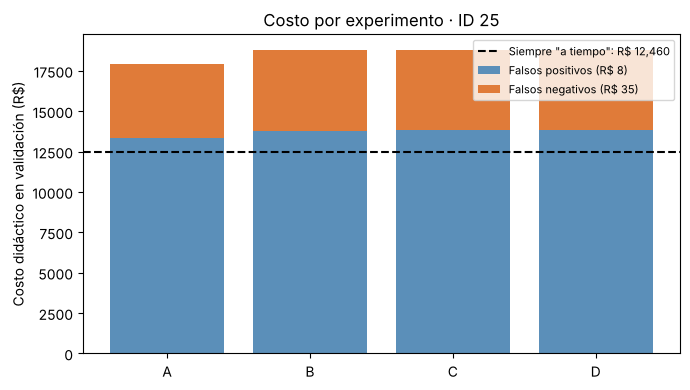

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
etiquetas = list(tabla_costos.index)
ax.bar(etiquetas, tabla_costos['costo_fp_brl'], label='Falsos positivos (R$ 8)', color='#5b8fb9')
ax.bar(etiquetas, tabla_costos['costo_fn_brl'], bottom=tabla_costos['costo_fp_brl'],
       label='Falsos negativos (R$ 35)', color='#e07b39')
ax.axhline(costo_referencia, color='black', linestyle='--',
           label=f'Siempre "a tiempo": R$ {costo_referencia:,.0f}')
ax.set_ylabel('Costo didáctico en validación (R$)')
ax.set_title('Costo por experimento · ID 25')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('reports/S14_costos_ID_25.png', dpi=150)
plt.show()

### Interpretación 3. Elección del modelo y decisión empresarial

**Respuesta:** Los costos en validación son: **A = R$ 17.945** (1.670 FP = R$ 13.360 y 131 FN = R$ 4.585), **B = R$ 18.765** (1.720 FP y 143 FN), **C = R$ 18.810** (1.730 FP y 142 FN) y **D = R$ 18.786** (1.727 FP y 142 FN). Pasar de A a B con PCA añade R$ 820 (+4.6 %): 50 falsas alarmas más y 12 retrasos más sin detectar. C y D frente a B difieren en solo R$ 45 y R$ 21, es decir, la regularización prácticamente no cambia el costo.

**Elección entre A–D: modelo A.** En esta comparación los tres criterios de la pregunta de análisis coinciden: A tiene la mayor Accuracy (0.657), el mayor Recall (0.632) y el menor costo, así que dentro de A–D no hay conflicto entre «más aciertos», «más tardíos identificados» y «menor costo». Además es el más simple, y ni PCA ni modificar `C` aportaron mejora.

**Pero el conflicto aparece frente a la referencia trivial.** El modelo que siempre predice «a tiempo» tiene Accuracy 0.932 (la más alta), Recall 0 y un costo de **R$ 12.460** (356 FN × R$ 35), menor que el de cualquiera de las cuatro configuraciones. A cuesta R$ 5.485 más (+44 %). Alertar todos los pedidos costaría R$ 39.152, de modo que los cuatro modelos son mucho mejores que eso, pero ninguno mejora a no alertar. La razón es que, con estos costos, alertar un pedido solo compensa si la probabilidad de que sea tardío supera 8 / (8 + 35) ≈ 18.6 %, y la precisión de A es 11.9 %: de 1.895 alertas, solo 225 eran retrasos reales.

**Decisión:** entre las cuatro alternativas elijo A, pero con el umbral de 0.50 y estos costos supuestos **no recomendaría poner el modelo en operación**: cada alerta tendría que acertar al menos 18.6 % de las veces para compensar. Una vía de mejora sería evaluar otro umbral o más información predictiva (como la propuesta de ruta y vendedor de la semana 12), tratándolo como un experimento aparte en validación y sin tocar la prueba reservada.

**Limitaciones:** los costos son supuestos didácticos (no incluyen el costo fijo de operar alertas ni el costo de intervenir un pedido bien detectado), el resultado depende de una sola partición de validación y las diferencias pequeñas entre B, C y D no son concluyentes.

## 6. Actividad 4. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

**Hipótesis (nivel de significancia α = 0,05):**

- H0: `valor_flete` tiene la misma distribución en entrenamiento y en validación.
- H1: las distribuciones de `valor_flete` en entrenamiento y validación son diferentes (prueba bilateral).

La prueba compara las dos distribuciones de una variable; **no compara el desempeño de los modelos**.

In [16]:
ALFA = 0.05
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

resultado = ks_2samp(flete_train, flete_valid, alternative='two-sided')
D, p = float(resultado.statistic), float(resultado.pvalue)
decision = 'Rechazar H0' if p < ALFA else 'No rechazar H0'

print(f'n entrenamiento = {len(flete_train):,} | n validación = {len(flete_valid):,}')
print(f'Estadístico D = {D:.4f}')
print(f'Valor p       = {p:.4f}')
print(f'Decisión con alfa = {ALFA}: {decision}')

descriptivas = pd.DataFrame({
    'entrenamiento': flete_train.describe(percentiles=[.25, .5, .75]),
    'validación': flete_valid.describe(percentiles=[.25, .5, .75]),
}).round(3)
print()
print(descriptivas.to_string())

# Empates: la prueba KS clásica supone una variable continua
print('\nValores distintos de valor_flete -> entrenamiento:', flete_train.nunique(),
      'de', len(flete_train), '| validación:', flete_valid.nunique(), 'de', len(flete_valid))
print('Pedidos con flete igual a 0 -> entrenamiento:', int((flete_train == 0).sum()),
      '| validación:', int((flete_valid == 0).sum()))

n entrenamiento = 24,500 | n validación = 5,250
Estadístico D = 0.0147
Valor p       = 0.3071
Decisión con alfa = 0.05: No rechazar H0

       entrenamiento  validación
count      24500.000    5250.000
mean          22.761      23.077
std           23.187      21.091
min            0.000       0.000
25%           13.858      14.100
50%           17.210      17.375
75%           23.910      24.840
max         1794.960     456.470

Valores distintos de valor_flete -> entrenamiento: 4593 de 24500 | validación: 2162 de 5250
Pedidos con flete igual a 0 -> entrenamiento: 81 | validación: 16


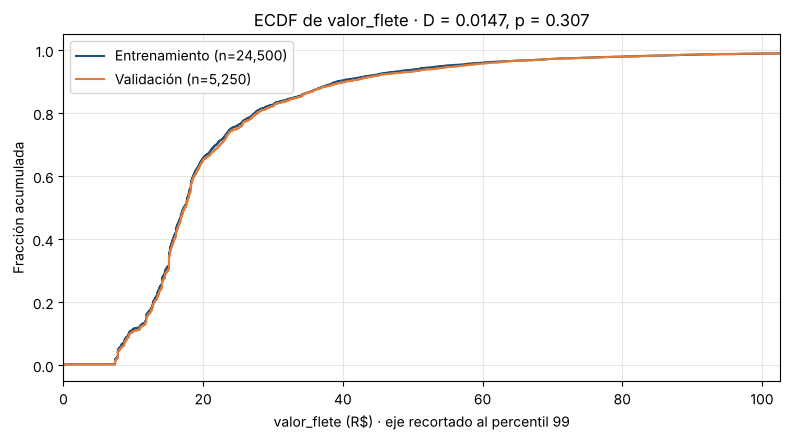

In [17]:
def ecdf(valores):
    v = np.sort(np.asarray(valores))
    return v, np.arange(1, len(v) + 1) / len(v)

fig, ax = plt.subplots(figsize=(8, 4.5))
for datos, etiqueta, color in [(flete_train, 'Entrenamiento', '#1f4e79'),
                               (flete_valid, 'Validación', '#e07b39')]:
    xs, ys = ecdf(datos)
    ax.step(xs, ys, where='post', label=f'{etiqueta} (n={len(datos):,})', color=color)
ax.set_xlim(0, float(np.percentile(pd.concat([flete_train, flete_valid]), 99)))
ax.set_xlabel('valor_flete (R$) · eje recortado al percentil 99')
ax.set_ylabel('Fracción acumulada')
ax.set_title(f'ECDF de valor_flete · D = {D:.4f}, p = {p:.3f}')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig('reports/S14_ks_valor_flete_ID_25.png', dpi=150)
plt.show()

### Interpretación 4. Prueba KS

**Respuesta:** Se compararon 24.500 pedidos de entrenamiento con 5.250 de validación. El estadístico fue **D = 0.0147** (la separación vertical máxima entre las dos ECDF) y el **valor p = 0.307**. Como p ≥ 0.05, **no se rechaza H0** al 5 %: no hay evidencia suficiente de que la distribución de `valor_flete` difiera entre ambas particiones. Esto es coherente con las medidas descriptivas: mediana 17.21 frente a 17.38, primer cuartil 13.86 frente a 14.10 y tercer cuartil 23.91 frente a 24.84, y con que la partición fue aleatoria y estratificada por `is_late`.

**Qué no significa:** no rechazar H0 no demuestra que las distribuciones sean idénticas, ni que el modelo esté validado, ni que una configuración sea mejor que otra; la prueba solo mira una variable (de las 28) y no usa predicciones.

**Limitación metodológica:** la prueba KS clásica se formula para variables continuas, y `valor_flete` tiene muchos valores repetidos (importes en centavos): solo hay 4.593 valores distintos en los 24.500 pedidos de entrenamiento y 2.162 en los 5.250 de validación, además de 81 y 16 pedidos con flete igual a 0. Con tantos empates el valor p debe leerse con cautela. Además, el valor p no mide la magnitud de la diferencia (para eso sirven D, la gráfica y los cuartiles) y una partición aleatoria no garantiza que los pedidos futuros se comporten igual.

## Conclusión general

**Pregunta de análisis: ¿más aciertos, más entregas tardías identificadas o menor costo?** Entre las cuatro configuraciones la respuesta no se divide: el modelo A (sin PCA, C = 1.0) tiene la mayor Accuracy (0.657), el mayor Recall (0.632) y el menor costo (R$ 17.945). El conflicto aparece solo frente al modelo que siempre predice «a tiempo»: tiene la mayor Accuracy (0.932) y el menor costo (R$ 12.460), pero no detecta ningún retraso. Por eso Accuracy sola no sirve en este problema, y el criterio que decide es el costo de los errores junto con el Recall.

**Qué aprendí con mi muestra (ID 25):**

1. Reducir de 24 a 15 variables numéricas con PCA no mejoró nada; empeoró Recall, F1, AP y costo. Resumir varianza no es lo mismo que conservar capacidad predictiva.
2. Cambiar `C` entre 0.1 y 10 casi no movió los resultados, y el F1 de entrenamiento y validación es casi igual: el problema no es sobreajuste.
3. El KS no encontró diferencia entre las distribuciones de `valor_flete` de entrenamiento y validación (p = 0.307), con la cautela por los valores repetidos; no dice nada sobre cuál modelo es mejor.
4. Con el umbral de 0.50 y los costos supuestos, ninguno de los cuatro modelos justifica operar como sistema automático de alertas: la precisión (0.119) está por debajo del punto de equilibrio (0.186).

**Hechos y supuestos:** son hechos observados las métricas, los FP, los FN y los costos en validación. Son supuestos los costos de R$ 8 y R$ 35, el umbral de 0.50 y que esta validación represente pedidos futuros. Las lecturas sobre por qué PCA empeoró el modelo son inferencias, no pruebas.

**Siguiente paso (no ejecutado aquí):** tratar como experimento aparte un cambio del umbral o variables nuevas (por ejemplo la ruta entre el estado del vendedor y el del cliente, propuesta en la semana 12), evaluado en validación y sin tocar la prueba final, que sigue reservada.

## 7. Autoverificación

Comprobaciones de que el cuaderno es reproducible y de que no se usó la prueba para elegir modelos.

In [18]:
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250)
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert huella_muestra == '2bceba3982e4'

# PCA: el número de componentes de la curva coincide con el que usa el pipeline
assert n_componentes == int(modelos['B'][0].named_transformers_['numericas'][-1].n_components_)
assert varianza_acum[n_componentes - 1] >= UMBRAL_VARIANZA > varianza_acum[n_componentes - 2]

# Los cuatro experimentos: misma partición, mismo umbral, mismos pesos de clase
assert list(resultados.index) == ['A', 'B', 'C', 'D']
assert all(len(p_) == len(y_valid) for p_ in preds.values())
assert all(m_[-1].class_weight == 'balanced' for m_ in modelos.values())
assert [m_[-1].C for m_ in modelos.values()] == [1.0, 1.0, 0.1, 10.0]
assert bool(resultados['convergio'].all()), 'Algún modelo no convergió: revise max_iter.'

# Costos y KS
for nombre in resultados.index:
    r = resultados.loc[nombre]
    assert np.isclose(r['costo_brl'], 8 * r['fp'] + 35 * r['fn'])
    assert r['tn'] + r['fp'] + r['fn'] + r['tp'] == len(y_valid)
assert 0 <= D <= 1 and 0 <= p <= 1
print('Autoverificación superada.')

Autoverificación superada.


## 8. Registro de resultados

Se guardan en `reports/`: la bitácora de experimentos (CSV), el reporte completo (JSON), el resumen del análisis (Markdown) y las tres gráficas. No se publican los datos originales ni la muestra de pedidos.

In [19]:
import sys
import sklearn
import scipy

# --- Bitácora de experimentos (una fila por configuración) ---
bitacora = resultados.reset_index().copy()
bitacora.insert(0, 'laboratorio', 'S14')
bitacora.insert(1, 'id_estudiante', identificador)
bitacora.insert(2, 'semilla', semilla)
bitacora.insert(3, 'huella_muestra', huella_muestra)
bitacora['preprocesamiento'] = np.where(
    bitacora['pca'], 'mediana+StandardScaler+PCA(90%) | moda+OneHot',
    'mediana+StandardScaler | moda+OneHot')
bitacora['class_weight'] = 'balanced'
bitacora['umbral'] = UMBRAL_CLASIFICACION
ruta_csv = Path(f'reports/S14_registro_experimentos_ID_{identificador}.csv')
bitacora.round(6).to_csv(ruta_csv, index=False)

# --- Reporte JSON ---
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'scipy': scipy.__version__,
    'n_muestra': len(muestra), 'n_train': len(train),
    'n_valid': len(valid), 'n_test': len(test),
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'huella_muestra': huella_muestra,
    'umbral_clasificacion': UMBRAL_CLASIFICACION,
    'costos_supuestos_brl': {'falso_positivo': COSTO_FP, 'falso_negativo': COSTO_FN},
    'pca': {
        'variables_numericas_iniciales': len(columnas_numericas),
        'umbral_varianza': UMBRAL_VARIANZA,
        'componentes_retenidas': n_componentes,
        'varianza_acumulada_retenida': float(varianza_acum[n_componentes - 1]),
        'varianza_primera_componente': float(varianza[0]),
    },
    'experimentos': {
        nombre: {
            'descripcion': EXPERIMENTOS[nombre]['descripcion'],
            'usa_pca': bool(EXPERIMENTOS[nombre]['pca']),
            'C': EXPERIMENTOS[nombre]['C'],
            'columnas_clasificador': int(resultados.loc[nombre, 'columnas_clasificador']),
            'metricas_validacion': {k: float(resultados.loc[nombre, k]) for k in metricas},
            'f1_entrenamiento': float(resultados.loc[nombre, 'f1_train']),
            'fp': int(resultados.loc[nombre, 'fp']), 'fn': int(resultados.loc[nombre, 'fn']),
            'costo_brl': float(resultados.loc[nombre, 'costo_brl']),
        } for nombre in resultados.index
    },
    'referencia_siempre_a_tiempo': {
        'accuracy': float(accuracy_score(y_valid, pred_ref)),
        'fn': int(fn_r), 'costo_brl': float(costo_referencia)},
    'referencia_alertar_todo': {'costo_brl': float(costo_alertar_todo)},
    'modelo_elegido': mejor,
    'ks_valor_flete': {
        'n_train': int(len(flete_train)), 'n_valid': int(len(flete_valid)),
        'estadistico_D': D, 'valor_p': p, 'alfa': ALFA, 'decision': decision},
}
ruta_json = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')

# --- Resumen del análisis (Markdown) ---
fila = lambda n: resultados.loc[n]
lineas_tabla = '\n'.join(
    f"| {n} | {'Sí' if EXPERIMENTOS[n]['pca'] else 'No'} | {EXPERIMENTOS[n]['C']} | "
    f"{fila(n)['accuracy']:.3f} | {fila(n)['precision']:.3f} | {fila(n)['recall']:.3f} | "
    f"{fila(n)['f1']:.3f} | {fila(n)['ap']:.3f} | {int(fila(n)['fp']):,} | {int(fila(n)['fn']):,} | "
    f"R$ {fila(n)['costo_brl']:,.0f} |" for n in resultados.index)
resumen = f'''# Resumen S14 · PCA y evaluación de mejoras · ID {identificador}

Muestra: {len(muestra):,} pedidos (huella `{huella_muestra}`), validación de {len(valid):,} pedidos
({int(y_valid.sum())} tardíos). Umbral 0.50, `class_weight='balanced'`. La prueba final no se usó.

## PCA
{len(columnas_numericas)} variables numéricas -> {n_componentes} componentes
({100 * varianza_acum[n_componentes - 1]:.2f} % de varianza acumulada). El clasificador recibe
{int(fila('B')['columnas_clasificador'])} columnas con PCA frente a {int(fila('A')['columnas_clasificador'])} sin PCA.

## Comparación en validación
| Exp. | PCA | C | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo (8·FP+35·FN) |
|---|---|---|---|---|---|---|---|---|---|---|
{lineas_tabla}

Referencia "siempre a tiempo": Accuracy {accuracy_score(y_valid, pred_ref):.3f}, Recall 0, costo R$ {costo_referencia:,.0f}.
Referencia "alertar todos": Recall 1, costo R$ {costo_alertar_todo:,.0f}.

## Sobreajuste (F1 entrenamiento frente a validación)
A: {fila('A')['f1_train']:.3f} y {fila('A')['f1']:.3f} | B: {fila('B')['f1_train']:.3f} y {fila('B')['f1']:.3f} | C: {fila('C')['f1_train']:.3f} y {fila('C')['f1']:.3f} | D: {fila('D')['f1_train']:.3f} y {fila('D')['f1']:.3f}.
Brecha máxima: {(resultados['f1_train'] - resultados['f1']).max():.3f}; no hay señal de sobreajuste, por eso cambiar C casi no tiene efecto.

## Conclusión
- Modelo elegido entre A-D: **{mejor}** (menor costo y mejor desempeño en todas las métricas).
- PCA (B frente a A) empeoró Recall, F1, AP y costo; cambiar C (C y D frente a B) casi no modificó nada.
- Ninguna configuración supera en costo a la referencia trivial con los costos supuestos
  (la precisión de A es {fila('A')['precision']:.3f} y el punto de equilibrio es {precision_equilibrio:.3f}); no se recomienda operar con umbral 0.50.
- KS sobre `valor_flete` (entrenamiento frente a validación): D = {D:.4f}, p = {p:.3f} -> {decision} al 5 %.
  No demuestra que las distribuciones sean idénticas; hay muchos empates en los importes.
- Limitaciones: costos supuestos, una sola partición de validación, sin pruebas de comparación entre modelos.
'''
ruta_md = Path(f'reports/S14_resumen_ID_{identificador}.md')
ruta_md.write_text(resumen, encoding='utf-8')
print('Archivos en reports/:')
for f in sorted(Path('reports').glob('S14_*')):
    print(' -', f)

# En Colab, descarga los archivos para conservarlos fuera de la sesión.
try:
    from google.colab import files
    for f in sorted(Path('reports').glob('S14_*')):
        files.download(str(f))
except Exception:
    print('Si no se descargaron automáticamente, guarde manualmente la carpeta reports/.')

Archivos en reports/:
 - reports/S14_costos_ID_25.png
 - reports/S14_ks_valor_flete_ID_25.png
 - reports/S14_registro_experimentos_ID_25.csv
 - reports/S14_resultados_ID_25.json
 - reports/S14_resumen_ID_25.md
 - reports/S14_varianza_acumulada_ID_25.png
Si no se descargaron automáticamente, guarde manualmente la carpeta reports/.
